# 3. Events and the design matrix

**What you will learn**
- What an `events.tsv` looks like and what the dummy volumes setting does.
- How events become a design matrix (HRF convolution), and how the HRF choice changes it.
- How to read the FitLins design matrix: correlations between regressors and contrast VIFs.

Data comes live from OpenNeuro: raw **events** from `s3://openneuro.org/` and the FitLins **design matrices** from
`s3://openneuro-derivatives/fitlins/`. Change `DATASET`/`TASK` to explore another study.

In [1]:
import json, re, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 140)

# Make `nb_utils` importable whether Jupyter was started in notebooks/ or at the repo root
NB_DIR = Path.cwd() if (Path.cwd() / "nb_utils.py").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB_DIR))
import nb_utils as nbu

REPO = NB_DIR.parent
SPECS = REPO / "statsmodel_specs"

import seaborn as sns
import urllib.request
from nilearn.glm.first_level import make_first_level_design_matrix
from nilearn.interfaces.bids import parse_bids_filename
from nilearn.plotting import plot_design_matrix
from openneuro_glmfitlins.qc.vif import gen_vifdf
from openneuro_glmfitlins.reports.groupmap import NOISE_REG

In [2]:
DATASET = "ds003425"
TASK = "learning"
SUBJECT = None   # e.g. "02"; None = first subject found
RUN = None       # e.g. "01"; None = first run found

## 1. Find a run on OpenNeuro

The run-level FitLins output holds one `*_design.tsv` per subject/run. We list them and pick one.

In [3]:
files = nbu.list_deriv_files(DATASET, TASK)
designs = pd.DataFrame([f for f in files if f["key"].endswith("_design.tsv")])
ents = designs["key"].map(lambda k: parse_bids_filename(k))
for e in ("sub", "ses", "run"):
    designs[e] = ents.map(lambda d: d.get(e))
print(f"{len(designs)} design matrices on OpenNeuro for {DATASET} {TASK}")

pick = designs if SUBJECT is None else designs[designs["sub"] == SUBJECT]
pick = pick if RUN is None else pick[pick["run"] == RUN]
row = pick.iloc[0]
sub, ses, run = row["sub"], row["ses"], row["run"]
print("Using:", row["key"].split("/")[-1])
designs.head()

72 design matrices on OpenNeuro for ds003425 learning
Using: sub-02_ses-01_task-learning_run-01_design.tsv


,key,size,sub,ses,run
0,fitlins/ds003425-fitlins/task-learning/node-ru...,97037,02,01,01
1,fitlins/ds003425-fitlins/task-learning/node-ru...,96824,02,01,02
2,fitlins/ds003425-fitlins/task-learning/node-ru...,96605,02,01,03
3,fitlins/ds003425-fitlins/task-learning/node-ru...,96835,02,01,04
4,fitlins/ds003425-fitlins/task-learning/node-ru...,96680,02,01,05


## 2. The raw events

Events say *what happened when*: `onset` and `duration` (seconds) and a `trial_type`. We read the one for the chosen
run directly from the raw dataset.

In [4]:
func_dir = f"{DATASET}/sub-{sub}/" + (f"ses-{ses}/" if ses else "") + "func/"
stem = "_".join(p for p in [f"sub-{sub}", f"ses-{ses}" if ses else None, f"task-{TASK}", f"run-{run}" if run else None] if p)
_, raw_files = nbu.s3_list(nbu.RAW_BUCKET, func_dir)
raw_keys = [f["key"] for f in raw_files]
ev_key = next(k for k in raw_keys if k.endswith("_events.tsv") and k.split("/")[-1].startswith(stem))
bold_key = ev_key.replace("_events.tsv", "_bold.json")

events = pd.read_csv(nbu.fetch(nbu.RAW_BUCKET, ev_key), sep="\t")
TR = json.loads(nbu.fetch(nbu.RAW_BUCKET, bold_key).read_text())["RepetitionTime"]
print(f"{ev_key.split('/')[-1]}: {len(events)} events, TR = {TR}s")
events.head()

sub-02_ses-01_task-learning_run-01_events.tsv: 12 events, TR = 2s


,onset,duration,trial_type
0,3.527389,6.5,4
1,23.555176,6.5,1
2,43.583047,6.5,2
3,63.610765,6.5,5
4,83.638697,6.5,5


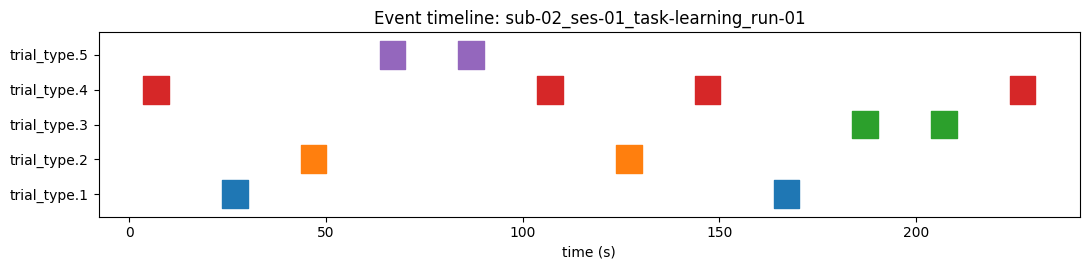

In [6]:
trial_types = sorted(events["trial_type"].unique(), key=str)
trial_colors = dict(zip(trial_types, plt.cm.tab10.colors))

fig, ax = plt.subplots(figsize=(11, 2.8))
for row_idx, trial_type in enumerate(trial_types):
    trial_events = events[events["trial_type"] == trial_type]
    onsets_and_durations = list(zip(trial_events["onset"], trial_events["duration"]))
    ax.broken_barh(onsets_and_durations, (row_idx - 0.4, 0.8), color=trial_colors[trial_type])

ax.set_yticks(range(len(trial_types)), [f"trial_type.{t}" for t in trial_types])
ax.set_xlabel("time (s)")
ax.set_title(f"Event timeline: {stem}")
plt.tight_layout()
plt.show()


## 3. Dummy volumes

The first scanner volumes are discarded as "dummy" volumes. `glmfitlins events` removes them from the preprocessed
BOLD data **and** the confounds file (written to `derivatives_alt`). The event onsets are not changed: they are
already relative to the first volume that is kept. The number to trim is stored in the study's basic-details file.

In [7]:
GITHUB_RAW = "https://raw.githubusercontent.com/demidenm/openneuro_glmfitlins/main/statsmodel_specs"
local = SPECS / DATASET / f"{DATASET}_basic-details.json"
if local.exists():
    basic = json.loads(local.read_text())
else:
    with urllib.request.urlopen(f"{GITHUB_RAW}/{DATASET}/{DATASET}_basic-details.json", timeout=60) as r:
        basic = json.loads(r.read())
DUMMIES = basic["Tasks"][TASK]["dummy_volumes"]
print(f"dummy volumes for {DATASET} {TASK}: {DUMMIES} (= {DUMMIES * TR:.1f}s of data removed from the start of each run)")

dummy volumes for ds003425 learning: 4 (= 8.0s of data removed from the start of each run)


## 4. The FitLins design matrix

Download the real run-level design matrix FitLins used. Columns are task regressors (`trial_type.N` and its
`_derivative`), then motion (`trans_*`, `rot_*`), drift (`cosine*`) and the `intercept`.

121 volumes x 39 regressors: 12 task, 27 nuisance/other


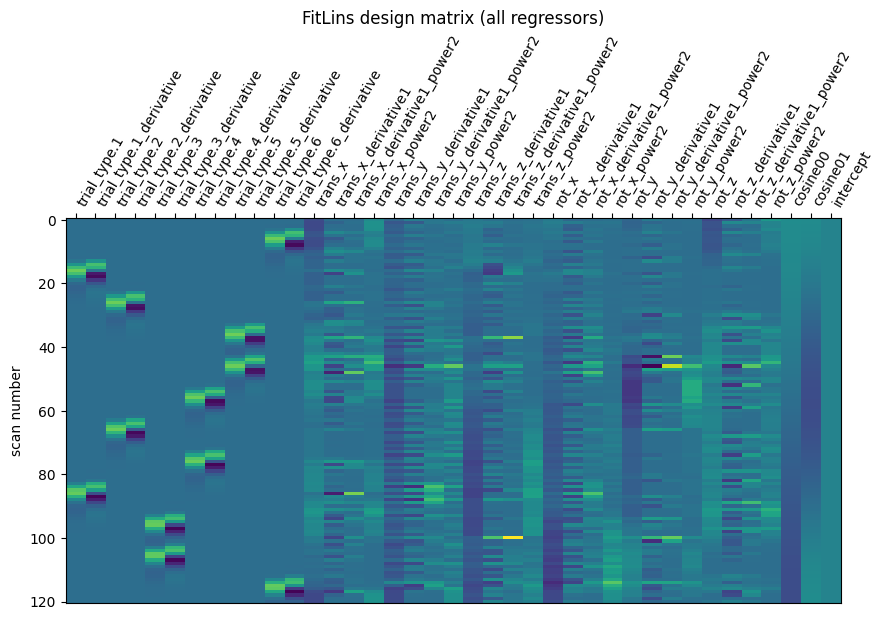

In [8]:
des = pd.read_csv(nbu.fetch(nbu.DERIV_BUCKET, row["key"]), sep="\t")
nuis_cols = [c for c in des.columns if any(n in c for n in NOISE_REG) or c in ("intercept", "constant")]
task_cols = [c for c in des.columns if c not in nuis_cols]
print(f"{des.shape[0]} volumes x {des.shape[1]} regressors: {len(task_cols)} task, {len(nuis_cols)} nuisance/other")

fig, ax = plt.subplots(figsize=(10, 5))
plot_design_matrix(des, ax=ax); ax.set_title("FitLins design matrix (all regressors)")
plt.show()

## 5. Rebuild it yourself and change the HRF

With `nilearn` we can rebuild the task part from the raw events . Edit `HRF` to see
how the model changes: `"spm"`, `"glover"`, `"spm + derivative"`, ... `"spm"` is what the spec uses (with its derivative).

In [9]:
HRF = "spm + derivative"        # try: "spm", "glover", "glover + derivative"
n_scans = des.shape[0]
frame_times = np.arange(n_scans) * TR

def build_dm(hrf_model, ev=events):
    ev = pd.DataFrame({"onset": ev["onset"], "duration": ev["duration"],
                       "trial_type": "trial_type." + ev["trial_type"].astype(str)})
    return make_first_level_design_matrix(frame_times, ev, hrf_model=hrf_model, drift_model=None)

mine = build_dm(HRF)
shared = [c for c in task_cols if c in mine.columns]
r = {c: np.corrcoef(mine[c], des[c])[0, 1] for c in shared}
print(f"Correlation of rebuilt vs. FitLins regressors ({HRF}):")
pd.Series(r, name="r").round(3).to_frame().T

Correlation of rebuilt vs. FitLins regressors (spm + derivative):


,trial_type.1,trial_type.1_derivative,trial_type.2,trial_type.2_derivative,trial_type.3,trial_type.3_derivative,trial_type.4,trial_type.4_derivative,trial_type.5,trial_type.5_derivative
r,0.969,0.924,0.979,0.948,0.913,0.804,0.656,0.643,0.984,0.964


High correlations (close to 1) mean the rebuilt regressor matches FitLins. Lower values are expected where this
repository applies an **event fix** to the raw events: for ds003425 the first and last CS- trials are split into a
separate `trial_type.6`, so `trial_type.4` and `5` in the FitLins design differ from the raw events. The dataset's
fix lives in `src/openneuro_glmfitlins/events/datasets/<dataset>.py`.

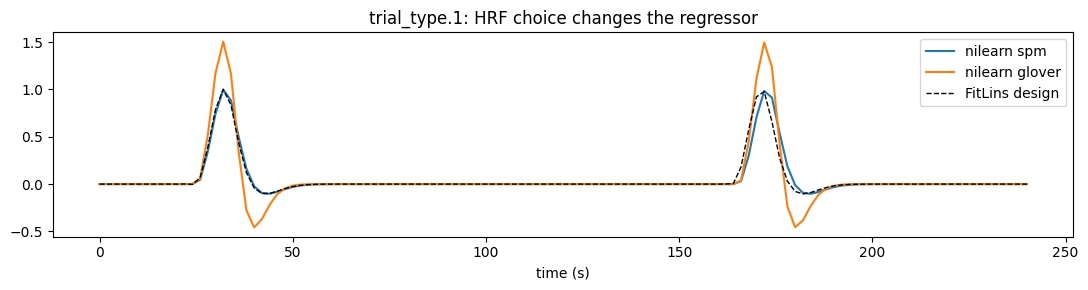

In [10]:
cond = f"trial_type.{conds[0]}"
fig, ax = plt.subplots(figsize=(11, 3))
for hrf in ["spm", "glover"]:
    ax.plot(frame_times, build_dm(hrf)[cond], label=f"nilearn {hrf}")
ax.plot(frame_times, des[cond], "k--", lw=1, label="FitLins design")
ax.set_xlabel("time (s)"); ax.set_title(f"{cond}: HRF choice changes the regressor"); ax.legend()
plt.tight_layout(); plt.show()

The FitLins regressor (dashed) should sit on the `spm` line. `glover` has a different shape, so contrast estimates
would differ slightly.

## 6. Regressor correlations and VIF

Highly correlated regressors make contrast estimates noisy. The **variance inflation factor (VIF)** compares a
contrast's variance with the variance it would have if regressors were uncorrelated: a VIF near 1 is ideal, and
larger values mean less efficient estimates (a commonly used rule of thumb is to look closely above ~5).

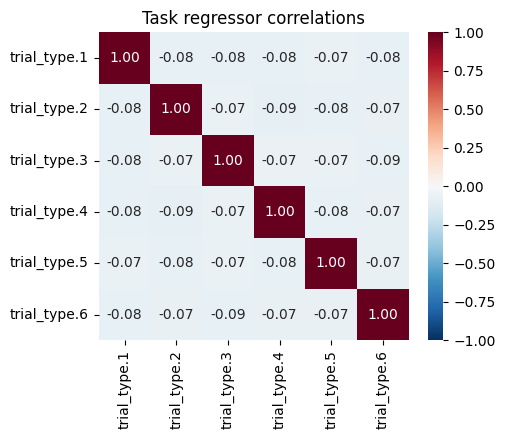

In [11]:
core = [c for c in task_cols if not c.endswith("_derivative")]
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(des[core].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Task regressor correlations"); plt.show()

{'VCSPvVCSN': '1*`trial_type.2` - 1*`trial_type.4`', 'ICSPvICSN': '1*`trial_type.3` - 1*`trial_type.5`', 'VCSPshck': '1*`trial_type.1`'}


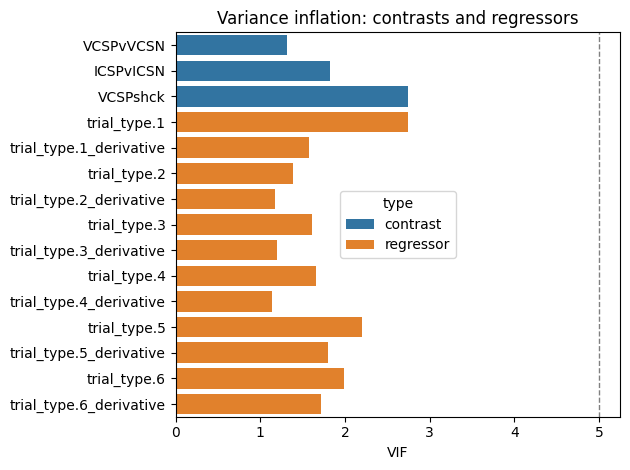

,type,name,value
0,contrast,VCSPvVCSN,1.32
1,contrast,ICSPvICSN,1.82
2,contrast,VCSPshck,2.74
3,regressor,trial_type.1,2.74
4,regressor,trial_type.1_derivative,1.58
5,regressor,trial_type.2,1.38
6,regressor,trial_type.2_derivative,1.18
7,regressor,trial_type.3,1.61
8,regressor,trial_type.3_derivative,1.19
9,regressor,trial_type.4,1.65


In [12]:
# Build the contrast expressions the same way as notebook 2 (weights x conditions)
with open(SPECS / DATASET / f"{DATASET}-{TASK}_contrasts.json") as f:
    con_defs = json.load(f)["Contrasts"]
con_expr = {c["Name"]: " + ".join(f"{w}*`{cond}`" for cond, w in zip(c["ConditionList"], c["Weights"])).replace(" + -", " - ")
            for c in con_defs if all(cond in des.columns for cond in c["ConditionList"])}
print(con_expr)

con_vifs, reg_vifs, vif_df = gen_vifdf(des, con_expr, nuis_cols)
ax = sns.barplot(data=vif_df, x="value", y="name", hue="type", orient="h")
ax.axvline(5, color="grey", ls="--", lw=1); ax.set_xlabel("VIF"); ax.set_ylabel("")
ax.set_title("Variance inflation: contrasts and regressors"); plt.tight_layout(); plt.show()
vif_df.round(2)

**Try it:** set `DATASET`/`TASK` to another study from notebook 1's list, or lower `n_scans` / change `HRF` and watch
the VIF change. The group report (notebook 5) repeats the VIF check for every design matrix.

**Next:** [04_inspect_fitlins_outputs.ipynb](04_inspect_fitlins_outputs.ipynb)